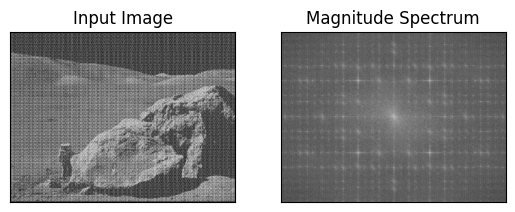

In [12]:
import numpy as np
import cv2 as cv
from matplotlib import pyplot as plt
 
img = cv.imread('periodic_noise.JPG', cv.IMREAD_GRAYSCALE)
 
dft = cv.dft(np.float32(img),flags = cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)
 
magnitude_spectrum = 20*np.log(cv.magnitude(dft_shift[:,:,0],dft_shift[:,:,1]))
 
plt.subplot(121),plt.imshow(img, cmap = 'gray')
plt.title('Input Image'), plt.xticks([]), plt.yticks([])
plt.subplot(122),plt.imshow(magnitude_spectrum, cmap = 'gray')
plt.title('Magnitude Spectrum'), plt.xticks([]), plt.yticks([])
plt.show()

In [13]:
#Filter creating
# Low pass filter
mask = np.zeros((img.shape[0],img.shape[1],2),np.uint8)
centerX, centerY = (int(img.shape[0] / 2),int(img.shape[1] / 2))
mask[centerX-50:centerX+50, centerY - 50:centerY+50,:] = 1

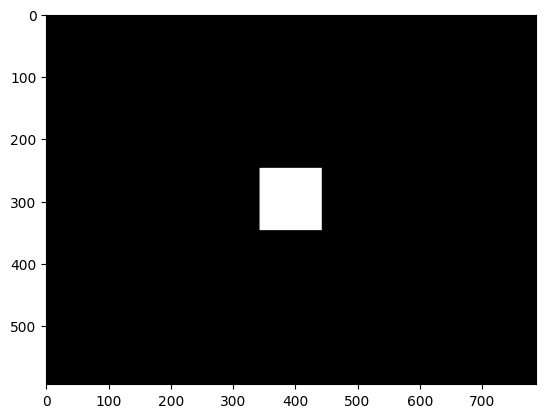

In [14]:
plt.imshow(mask[:,:,0], cmap = 'gray')

In [15]:
# Filtering
dft_shift = dft_shift*mask

C:\Users\PC\AppData\Local\Temp\ipykernel_9768\3830399572.py:1: RuntimeWarning: divide by zero encountered in log
  filtering_magn_res = 20*np.log(cv.magnitude(dft_shift[:,:,0],dft_shift[:,:,1]))


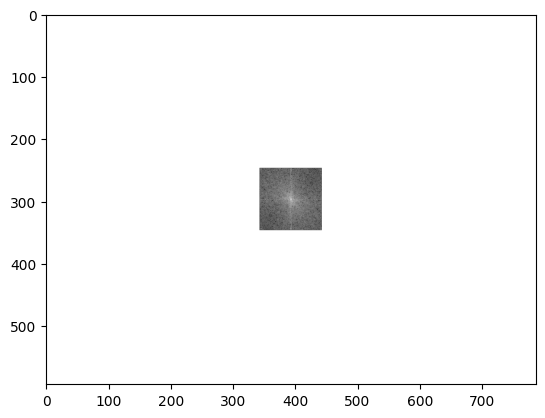

In [16]:
filtering_magn_res = 20*np.log(cv.magnitude(dft_shift[:,:,0],dft_shift[:,:,1]))
plt.imshow(filtering_magn_res, cmap='gray')

In [17]:
#fshift = dft_shift*mask
f_ishift = np.fft.ifftshift(dft_shift)
img_back = cv.idft(f_ishift)
img_back = cv.magnitude(img_back[:,:,0],img_back[:,:,1])

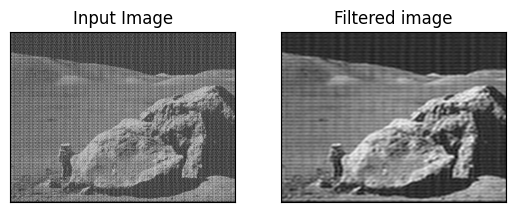

In [18]:
plt.subplot(121),plt.imshow(img, cmap = 'gray')
plt.title('Input Image'), plt.xticks([]), plt.yticks([])
plt.subplot(122),plt.imshow(img_back, cmap = 'gray')
plt.title('Filtered image'), plt.xticks([]), plt.yticks([])
plt.show()

In [19]:
# Реализуйте высокочастотную фильтрацию на основе ядра Гаусса
# Реализуйте вычисление свертки с помощью преобразования Фурье
# Реализуйте удаление периодического шума с помощью преобразования Фурье

## Домашнее задание

### 1. Высокочастотная фильтрация с помощью гауссова ядра

Размываем изображение гауссовым фильтром и вычитаем результат из исходного изображения. Так сохраняются высокочастотные детали и границы.

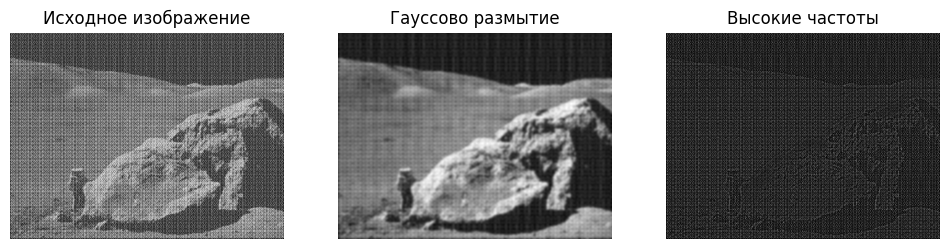

In [20]:
# Высокочастотная составляющая: оригинал минус гауссово размытие
blur = cv.GaussianBlur(img, (0, 0), sigmaX=3)
high_pass = cv.subtract(img, blur)

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plt.imshow(img, cmap='gray')
plt.title('Исходное изображение')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(blur, cmap='gray')
plt.title('Гауссово размытие')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(high_pass, cmap='gray')
plt.title('Высокие частоты')
plt.axis('off')
plt.show()

### 2. Вычисление свёртки через преобразование Фурье

Выполняем свёртку изображения с гауссовым ядром в частотной области. Размеры дополняются до размера полной свёртки, после обратного преобразования берётся центральная область исходного размера.

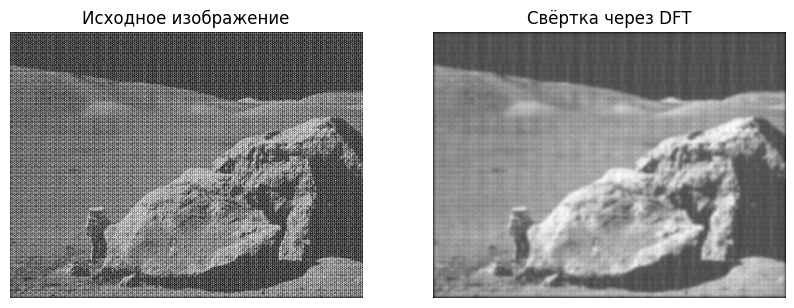

In [21]:
kernel = cv.getGaussianKernel(21, 3)
kernel = kernel @ kernel.T

# Размер для полной линейной свёртки
H = cv.getOptimalDFTSize(img.shape[0] + kernel.shape[0] - 1)
W = cv.getOptimalDFTSize(img.shape[1] + kernel.shape[1] - 1)

image_pad = np.zeros((H, W), np.float32)
kernel_pad = np.zeros((H, W), np.float32)
image_pad[:img.shape[0], :img.shape[1]] = img.astype(np.float32)
kernel_pad[:kernel.shape[0], :kernel.shape[1]] = kernel

# Перенос центра ядра в начало массива для корректной свёртки в DFT
kernel_pad = np.roll(kernel_pad, -(kernel.shape[0] // 2), axis=0)
kernel_pad = np.roll(kernel_pad, -(kernel.shape[1] // 2), axis=1)

F_image = cv.dft(image_pad, flags=cv.DFT_COMPLEX_OUTPUT)
F_kernel = cv.dft(kernel_pad, flags=cv.DFT_COMPLEX_OUTPUT)
F_result = cv.mulSpectrums(F_image, F_kernel, 0)
convolution = cv.idft(F_result, flags=cv.DFT_SCALE | cv.DFT_REAL_OUTPUT)

# Результат той же размерности, что исходное изображение
convolution = convolution[:img.shape[0], :img.shape[1]]

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('Исходное изображение')
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(convolution, cmap='gray')
plt.title('Свёртка через DFT')
plt.axis('off')
plt.show()

### 3. Удаление периодического шума с помощью преобразования Фурье

Строим амплитудный спектр, находим симметричные яркие пики периодического шума и подавляем их гауссовыми режекторными фильтрами (notch filter). Затем выполняем обратное преобразование Фурье.

Найдено пиков периодического шума: 6


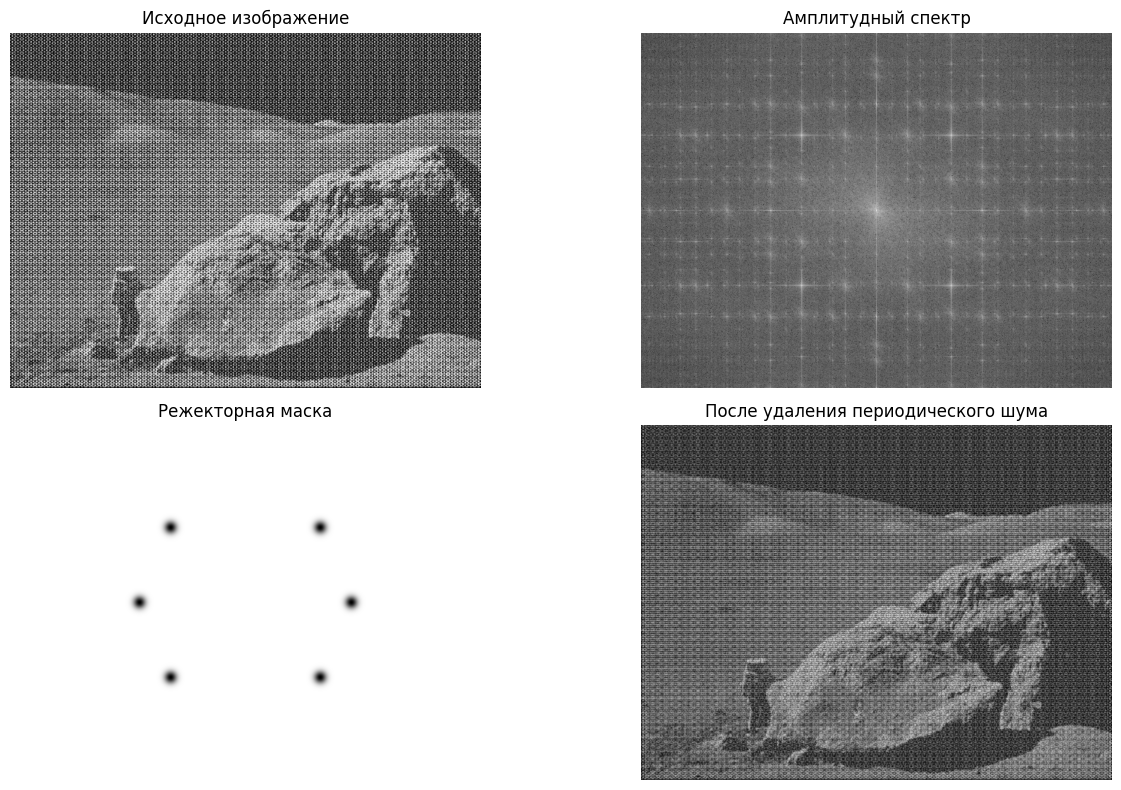

In [22]:
# Спектр изображения
dft = cv.dft(np.float32(img), flags=cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)
magnitude = cv.magnitude(dft_shift[:, :, 0], dft_shift[:, :, 1])
spectrum = 20 * np.log(magnitude + 1)

# Поиск локальных максимумов вне центральной области спектра
from scipy.ndimage import maximum_filter

h, w = img.shape
cy, cx = h // 2, w // 2
Y, X = np.ogrid[:h, :w]
spectrum_log = np.log1p(magnitude)
outside_center = (X - cx)**2 + (Y - cy)**2 > 35**2
local_max = spectrum_log == maximum_filter(spectrum_log, size=13)
threshold = np.percentile(spectrum_log[outside_center & local_max], 99.7)
peaks = np.argwhere(local_max & outside_center & (spectrum_log >= threshold))

# Гауссовы режекторные фильтры в точках пиков
notch_mask = np.ones((h, w), np.float32)
sigma = 7
for py, px in peaks:
    dy = np.minimum(np.abs(Y - py), h - np.abs(Y - py))
    dx = np.minimum(np.abs(X - px), w - np.abs(X - px))
    notch = 1 - np.exp(-(dx**2 + dy**2) / (2 * sigma**2))
    notch_mask *= notch.astype(np.float32)

filtered_shift = dft_shift * notch_mask[:, :, None]
inverse = cv.idft(
    np.fft.ifftshift(filtered_shift),
    flags=cv.DFT_SCALE | cv.DFT_COMPLEX_OUTPUT
)
denoised = cv.magnitude(inverse[:, :, 0], inverse[:, :, 1])

print('Найдено пиков периодического шума:', len(peaks))

plt.figure(figsize=(14, 8))
plt.subplot(2, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('Исходное изображение')
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(spectrum, cmap='gray')
plt.title('Амплитудный спектр')
plt.axis('off')

plt.subplot(2, 2, 3)
plt.imshow(notch_mask, cmap='gray')
plt.title('Режекторная маска')
plt.axis('off')

plt.subplot(2, 2, 4)
plt.imshow(denoised, cmap='gray')
plt.title('После удаления периодического шума')
plt.axis('off')
plt.tight_layout()
plt.show()

**Вывод:** гауссово высокочастотное выделение подчёркивает мелкие детали и границы. Свёртка через DFT даёт результат фильтрации в частотной области. Для удаления периодического шума подавляются симметричные пики спектра, соответствующие регулярной помехе; после обратного DFT периодический рисунок становится менее заметным.